In [25]:
import os
import time
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from sklearn.metrics import classification_report, f1_score

# --- 1. CONFIGURATION ---
PROJECT_DIR = os.path.abspath(".")
HOLDOUT_DIR = os.path.join(PROJECT_DIR, "live_demo_holdout")
MODEL_WEIGHTS_PATH = os.path.join(PROJECT_DIR, "best_baseline_roof_cnn.pth")

IMAGE_SIZE = (224, 224)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")

CLASS_NAMES = [
    "Class 0: Healthy",
    "Class 1: Maintenance",
    "Class 2: Retrofit Candidate"
]

FOLDER_TO_IDX = {
    "class_0_healthy": 0,
    "class_1_maintenance": 1,
    "class_2_retrofit": 2
}

# BGR colors for OpenCV HUD: Green (Healthy), Orange (Maintenance), Red (Retrofit)
CLASS_COLORS = {
    0: (40, 180, 40),
    1: (0, 165, 255),
    2: (40, 40, 220)
}


# --- 2. MODEL ARCHITECTURE DEFINITION ---
# NOTE: Ensure this class matches the exact CNN architecture saved by Ishmael/Key
class RoofConditionCNN(nn.Module):
    def __init__(self, num_classes=3, dropout_rate=0.5):
        super(RoofConditionCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# --- 3. LOAD MODEL & PREPROCESSING ---
eval_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

def load_trained_model(weights_path, device):
    model = RoofConditionCNN(num_classes=3).to(device)
    if os.path.exists(weights_path):
        checkpoint = torch.load(weights_path, map_location=device)
        # Support both raw state_dict and full model checkpoints
        if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
            model.load_state_dict(checkpoint["model_state_dict"])
        elif isinstance(checkpoint, dict):
            model.load_state_dict(checkpoint)
        else:
            model = checkpoint.to(device)
        print(f"[INFO] Successfully loaded trained weights: {weights_path}")
    else:
        print(f"[WARNING] Weights not found at '{weights_path}'.")
        print("[WARNING] Running in DRY-RUN mode with untrained weights so you can test the UI.")
    model.eval()
    return model


# --- 4. GATHER HOLDOUT IMAGES ---
def get_holdout_images(holdout_dir):
    samples = []
    if not os.path.exists(holdout_dir):
        print(f"[ERROR] Holdout folder not found: {holdout_dir}")
        return samples

    for root, _, files in os.walk(holdout_dir):
        parent_folder = os.path.basename(root).lower()
        true_label = FOLDER_TO_IDX.get(parent_folder, None)
        for file in sorted(files):
            if file.lower().endswith(VALID_EXTENSIONS):
                samples.append((os.path.join(root, file), true_label))
    return samples


# --- 5. LIVE PRESENTATION DEMO LOOP ---
def run_live_demo():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[INFO] Running inference on device: {device}")

    model = load_trained_model(MODEL_WEIGHTS_PATH, device)
    samples = get_holdout_images(HOLDOUT_DIR)

    if not samples:
        print(f"[ERROR] No images found in '{HOLDOUT_DIR}'. Add your 26 DJI drone photos first.")
        return

    print(f"[INFO] Loaded {len(samples)} unseen DJI Mini 3 Pro holdout images.")
    print("Controls: [SPACE / RIGHT ARROW] Next | [B / LEFT ARROW] Previous | [S] Save Screenshot | [Q] Quit\n")

    cv2.namedWindow("AIM 350 Live Drone Inference Demo", cv2.WINDOW_AUTOSIZE)
    try:
        cv2.setWindowProperty("AIM 350 Live Drone Inference Demo", cv2.WND_PROP_TOPMOST, 1)
    except Exception:
        pass

    y_true, y_pred = [], []
    recorded_indices = set()
    idx = 0

    while 0 <= idx < len(samples):
        img_path, true_idx = samples[idx]
        bgr_img = cv2.imread(img_path)
        if bgr_img is None:
            idx += 1
            continue

        # Convert BGR (OpenCV) to RGB (PIL) for exact torchvision preprocessing
        rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(rgb_img)
        input_tensor = eval_transforms(pil_img).unsqueeze(0).to(device)

        # Timed forward pass
        start_time = time.perf_counter()
        with torch.no_grad():
            logits = model(input_tensor)
            probs = F.softmax(logits, dim=1).cpu().numpy()[0]
        latency_ms = (time.perf_counter() - start_time) * 1000.0

        pred_idx = int(probs.argmax())
        confidence = probs[pred_idx] * 100.0

        # Log metrics once per holdout image if ground-truth folders exist
        if true_idx is not None and idx not in recorded_indices:
            y_true.append(true_idx)
            y_pred.append(pred_idx)
            recorded_indices.add(idx)

        # --- BUILD PRESENTATION DASHBOARD HUD ---
        # Left panel: 650x650 drone photo | Right panel: 400px telemetry sidebar
        photo_view = cv2.resize(bgr_img, (650, 650))
        canvas = cv2.copyMakeBorder(photo_view, 0, 0, 0, 420, cv2.BORDER_CONSTANT, value=(28, 28, 32))

        banner_color = CLASS_COLORS[pred_idx]
        cv2.rectangle(canvas, (650, 0), (1070, 95), banner_color, -1)
        cv2.putText(canvas, "PREDICTED CONDITION:", (668, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (240, 240, 240), 1)
        cv2.putText(canvas, CLASS_NAMES[pred_idx], (668, 68),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.72, (255, 255, 255), 2)

        # Metadata & Latency Readout
        filename = os.path.basename(img_path)
        cv2.putText(canvas, f"Sample: {idx + 1} / {len(samples)} ({filename[:22]})", (668, 135),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.52, (210, 210, 210), 1)
        cv2.putText(canvas, f"Inference Time: {latency_ms:.1f} ms ({device.type.upper()})", (668, 165),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.52, (180, 220, 255), 1)

        # Ground-Truth Verification Badge (if inside class_0 / class_1 / class_2 folders)
        if true_idx is not None:
            match = (pred_idx == true_idx)
            status_txt = "MATCH (CORRECT)" if match else "MISMATCH"
            status_col = (80, 230, 80) if match else (70, 70, 255)
            cv2.putText(canvas, f"Actual: {CLASS_NAMES[true_idx]}", (668, 205),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.52, (220, 220, 220), 1)
            cv2.putText(canvas, f"Status: {status_txt}", (668, 232),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.58, status_col, 2)
        else:
            cv2.putText(canvas, "Mode: Unlabeled Live Holdout", (668, 205),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.52, (170, 170, 170), 1)

        # Softmax Confidence Bar Chart
        cv2.putText(canvas, "Softmax Class Probabilities:", (668, 285),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.58, (255, 255, 255), 1)

        for c_idx, c_name in enumerate(CLASS_NAMES):
            pct = probs[c_idx] * 100.0
            y_top = 315 + c_idx * 85

            cv2.putText(canvas, f"{c_name}: {pct:.1f}%", (668, y_top),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.52, (230, 230, 230), 1)

            # Background bar track
            cv2.rectangle(canvas, (668, y_top + 12), (1040, y_top + 40), (55, 55, 60), -1)
            # Filled probability bar
            bar_width = int(3.72 * pct)
            cv2.rectangle(canvas, (668, y_top + 12), (668 + bar_width, y_top + 40), CLASS_COLORS[c_idx], -1)

        # Footer Controls
        cv2.putText(canvas, "[SPACE] Next  |  [B] Back  |  [S] Save Slide  |  [Q] Finish",
                    (668, 625), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (150, 150, 150), 1)

        cv2.imshow("AIM 350 Live Drone Inference Demo", canvas)
        print(f"[{idx+1:02d}/{len(samples):02d}] {filename} -> {CLASS_NAMES[pred_idx]} ({confidence:.1f}%) [{latency_ms:.1f} ms]")

        key = cv2.waitKey(0) & 0xFF
        if key in (ord('q'), 27):
            break
        elif key == ord('b'):
            idx = max(0, idx - 1)
        elif key == ord('s'):
            shot_name = f"demo_screenshot_{idx+1:02d}.jpg"
            cv2.imwrite(shot_name, canvas)
            print(f"  [SAVED SCREENSHOT] -> {shot_name}")
        else:
            idx += 1

    cv2.destroyAllWindows()

    # --- 6. PRINT FINAL HOLDOUT METRICS SUMMARY ---
    if y_true:
        macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
        print("\n" + "=" * 60)
        print("FINAL HOLDOUT TEST SUMMARY (DJI MINI 3 PRO IMAGERY)")
        print("=" * 60)
        print(f"Samples Evaluated: {len(y_true)} | Holdout Macro F1-Score: {macro_f1:.4f}\n")
        print(classification_report(
            y_true, y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            zero_division=0
        ))

if __name__ == "__main__":
    pass
    # run_live_demo()

In [26]:
import os

os.makedirs("live_demo_holdout", exist_ok=True)

print("Holdout folder created.")

Holdout folder created.


In [27]:
import zipfile
import os

zip_path = "drive-download-20261017T232421Z-1-001.zip"
extract_path = "live_demo_holdout"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Roof images extracted.")

Roof images extracted.


In [28]:
import os

files = []

for root, dirs, filenames in os.walk("live_demo_holdout"):
    for filename in filenames:
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            files.append(os.path.join(root, filename))

print("Holdout images found:", len(files))

Holdout images found: 26


In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_model = load_trained_model(
    "best_baseline_roof_cnn.pth",
    device
)

print("Baseline model load test complete.")

[INFO] Successfully loaded trained weights: best_baseline_roof_cnn.pth
Baseline model load test complete.


In [30]:
samples = get_holdout_images("live_demo_holdout")

print("Holdout samples detected:", len(samples))
print("First sample:", samples[0] if samples else "None")

Holdout samples detected: 26
First sample: ('live_demo_holdout/DJI_0242.JPG', None)


In [31]:
img_path, _ = samples[0]

image = Image.open(img_path).convert("RGB")
input_tensor = eval_transforms(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = test_model(input_tensor)
    probs = F.softmax(logits, dim=1).cpu().numpy()[0]

pred_idx = int(probs.argmax())
confidence = probs[pred_idx] * 100

print("Image:", img_path)
print("Prediction:", CLASS_NAMES[pred_idx])
print(f"Confidence: {confidence:.1f}%")
print("Probabilities:", probs)

Image: live_demo_holdout/DJI_0242.JPG
Prediction: Class 1: Maintenance
Confidence: 55.6%
Probabilities: [0.42000204 0.5555176  0.02448025]


[INFO] Successfully loaded trained weights: /content/best_baseline_roof_cnn.pth


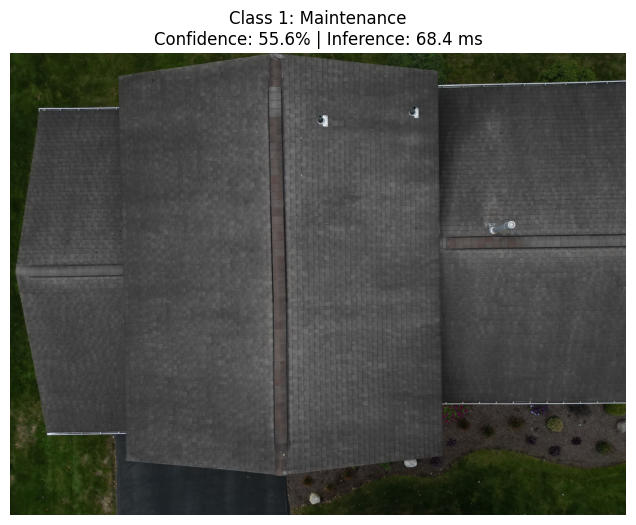

Image: DJI_0242.JPG
Prediction: Class 1: Maintenance
Confidence: 55.6%

Class probabilities:
Class 0: Healthy: 42.0%
Class 1: Maintenance: 55.6%
Class 2: Retrofit Candidate: 2.4%


In [32]:
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_trained_model(MODEL_WEIGHTS_PATH, device)
samples = get_holdout_images(HOLDOUT_DIR)

def show_demo(index=0):
    img_path, _ = samples[index]

    image = Image.open(img_path).convert("RGB")
    input_tensor = eval_transforms(image).unsqueeze(0).to(device)

    start_time = time.perf_counter()

    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=1).cpu().numpy()[0]

    latency_ms = (time.perf_counter() - start_time) * 1000

    pred_idx = int(probs.argmax())
    confidence = probs[pred_idx] * 100

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{CLASS_NAMES[pred_idx]}\n"
        f"Confidence: {confidence:.1f}% | Inference: {latency_ms:.1f} ms"
    )
    plt.show()

    print("Image:", os.path.basename(img_path))
    print("Prediction:", CLASS_NAMES[pred_idx])
    print(f"Confidence: {confidence:.1f}%")
    print()
    print("Class probabilities:")

    for i, class_name in enumerate(CLASS_NAMES):
        print(f"{class_name}: {probs[i] * 100:.1f}%")

show_demo(0)

In [33]:
import ipywidgets as widgets
from IPython.display import display

image_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(samples) - 1,
    step=1,
    description="Roof:",
    continuous_update=False
)

widgets.interact(show_demo, index=image_slider)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Roof:', max=25), Output()), _do…

<function __main__.show_demo(index=0)>

BASELINE CNN VALIDATION PERFORMANCE
Validation Accuracy: 0.5625
Macro F1: 0.5456

Confusion Matrix:
[[8 6 3]
 [1 7 4]
 [0 0 3]]


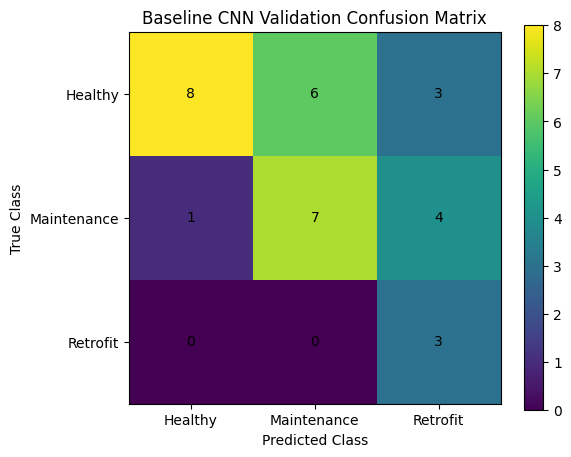

In [34]:
import numpy as np
import matplotlib.pyplot as plt

baseline_accuracy = 0.5625
baseline_macro_f1 = 0.5456

cm = np.array([
    [8, 6, 3],
    [1, 7, 4],
    [0, 0, 3]
])

print("BASELINE CNN VALIDATION PERFORMANCE")
print(f"Validation Accuracy: {baseline_accuracy:.4f}")
print(f"Macro F1: {baseline_macro_f1:.4f}")
print()
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Baseline CNN Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks([0, 1, 2], ["Healthy", "Maintenance", "Retrofit"])
plt.yticks([0, 1, 2], ["Healthy", "Maintenance", "Retrofit"])

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [35]:
print("LIVE DEMO DATA CHECK")
print("Real DJI roof images loaded:", len(samples))
print("First image:", os.path.basename(samples[0][0]))

LIVE DEMO DATA CHECK
Real DJI roof images loaded: 26
First image: DJI_0242.JPG
